data set https://www.kaggle.com/datasets/varpit94/amazon-stock-data

forecast khoảng giá dựa vào return của cổ phiếu AMZ sử dụng ARIMA

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/varpit94/amazon-stock-data/AMZN.csv


In [2]:
prices = pd.read_csv('/kaggle/input/datasets/varpit94/amazon-stock-data/AMZN.csv')

prices.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,1997-05-15,2.437500,2.500000,1.927083,1.958333,1.958333,72156000
1,1997-05-16,1.968750,1.979167,1.708333,1.729167,1.729167,14700000
2,1997-05-19,1.760417,1.770833,1.625000,1.708333,1.708333,6106800
3,1997-05-20,1.729167,1.750000,1.635417,1.635417,1.635417,5467200
4,1997-05-21,1.635417,1.645833,1.375000,1.427083,1.427083,18853200


In [3]:
prices['Date'] = pd.to_datetime(prices['Date'])
prices = prices.sort_values(
    ['Date']
).reset_index(drop=True)

prices['return'] = prices['Adj Close'].pct_change()

prices = prices.dropna(subset=['return'])

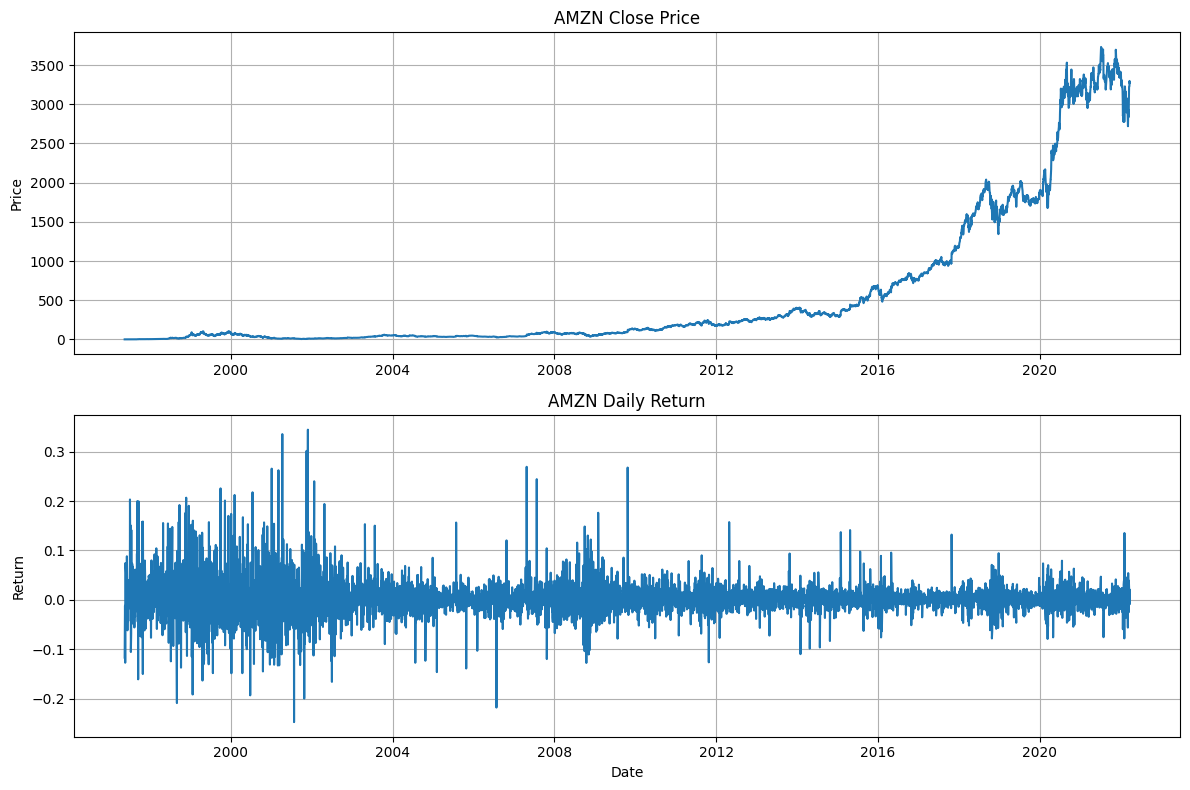

In [4]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(2, 1, figsize=(12, 8))

# Price
ax[0].plot(prices['Date'], prices['Adj Close'])
ax[0].set_title('AMZN Close Price')
ax[0].set_ylabel('Price')
ax[0].grid(True)

# Return
ax[1].plot(prices['Date'], prices['return'])
ax[1].set_title('AMZN Daily Return')
ax[1].set_ylabel('Return')
ax[1].set_xlabel('Date')
ax[1].grid(True)

plt.tight_layout()
plt.show()

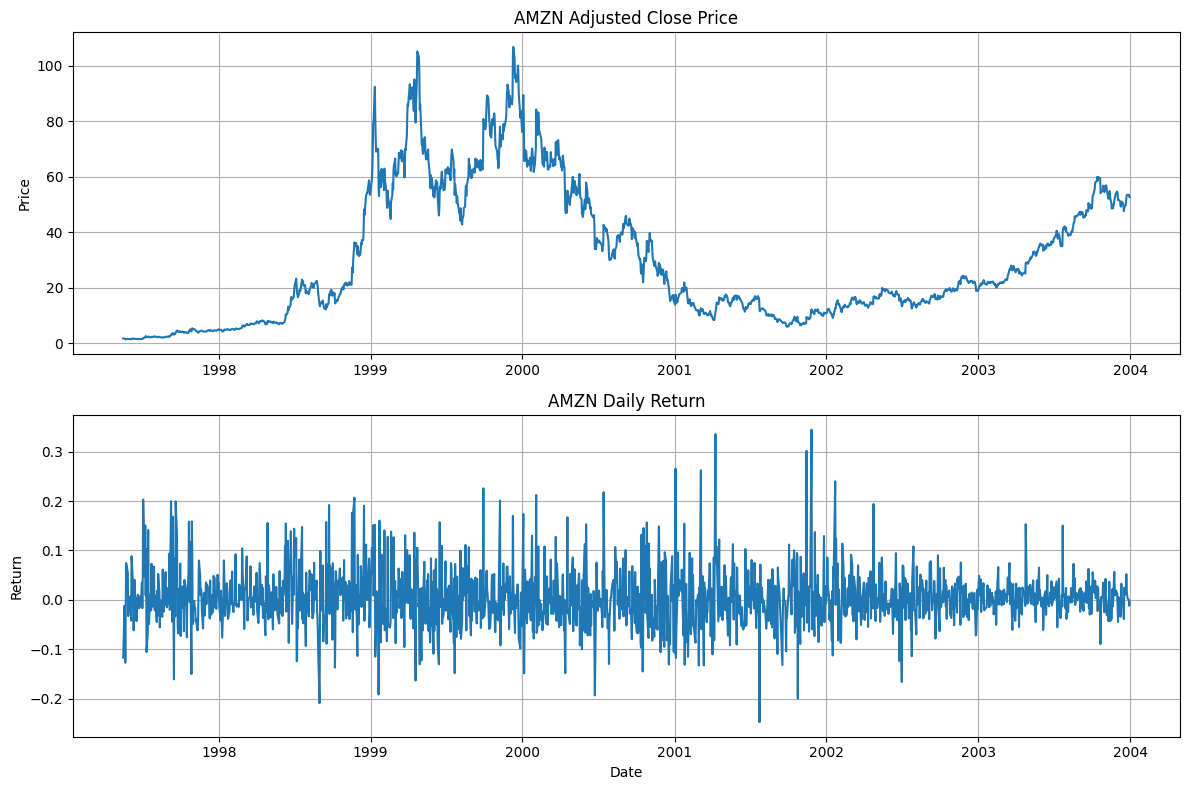

In [5]:
start_date = '1997-01-01'
end_date = '2003-12-31'

plot_data = prices[
    (prices['Date'] >= start_date) &
    (prices['Date'] <= end_date)
]

import matplotlib.pyplot as plt

fig, ax = plt.subplots(2, 1, figsize=(12, 8))

# Price
ax[0].plot(plot_data['Date'], plot_data['Adj Close'])
ax[0].set_title('AMZN Adjusted Close Price')
ax[0].set_ylabel('Price')
ax[0].grid(True)

# Return
ax[1].plot(plot_data['Date'], plot_data['return'])
ax[1].set_title('AMZN Daily Return')
ax[1].set_ylabel('Return')
ax[1].set_xlabel('Date')
ax[1].grid(True)

plt.tight_layout()
plt.show()

In [6]:
train = prices[
    prices['Date'] <= '2018-12-31'
].copy()

val = prices[
    (prices['Date'] >= '2019-01-01') &
    (prices['Date'] <= '2020-12-31')
].copy()

test = prices[
    prices['Date'] >= '2021-01-01'
].copy()

In [7]:
print("=== DATE RANGE ===")
print("Min date:", prices['Date'].min())
print("Max date:", prices['Date'].max())

print("\n=== UNIQUE DATE TYPE ===")
print(prices['Date'].dtype)

=== DATE RANGE ===
Min date: 1997-05-16 00:00:00
Max date: 2022-03-24 00:00:00

=== UNIQUE DATE TYPE ===
datetime64[ns]


Stationary check.


In [8]:
from statsmodels.tsa.stattools import adfuller

price = train['Adj Close'].dropna()

result = adfuller(price)

print("ADF Statistic:", result[0])
print("p-value:", result[1])

ADF Statistic: 1.3734031263001412
p-value: 0.9969899027359198


In [9]:
train_returns = train['return'].dropna()

result = adfuller(train_returns)

print("ADF Statistic:", result[0])
print("p-value:", result[1])

ADF Statistic: -12.446257975621588
p-value: 3.658942862392453e-23


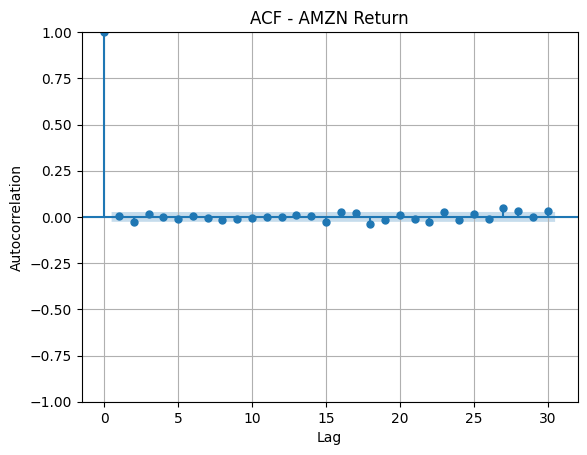

In [10]:
from statsmodels.graphics.tsaplots import plot_acf
import matplotlib.pyplot as plt

# Lấy return của tập train
train_return = train['return'].dropna()

# Vẽ ACF
plot_acf(train_return, lags=30)

plt.title('ACF - AMZN Return')
plt.xlabel('Lag')
plt.ylabel('Autocorrelation')
plt.grid(True)
plt.show()

In [11]:
from statsmodels.tsa.stattools import acf

acf_values, confint = acf(
    train_return,
    nlags=30,
    alpha=0.05
)

for lag in range(1, 31):
    lower, upper = confint[lag]

    significant = not (lower <= 0 <= upper)

    print(
        f"Lag {lag:2d}: "
        f"ACF={acf_values[lag]:.4f}, "
        f"CI=[{lower:.4f}, {upper:.4f}], "
        f"Significant={significant}"
    )

Lag  1: ACF=0.0060, CI=[-0.0205, 0.0326], Significant=False
Lag  2: ACF=-0.0281, CI=[-0.0547, -0.0016], Significant=True
Lag  3: ACF=0.0155, CI=[-0.0111, 0.0421], Significant=False
Lag  4: ACF=-0.0017, CI=[-0.0283, 0.0249], Significant=False
Lag  5: ACF=-0.0099, CI=[-0.0365, 0.0167], Significant=False
Lag  6: ACF=0.0077, CI=[-0.0189, 0.0343], Significant=False
Lag  7: ACF=-0.0036, CI=[-0.0302, 0.0230], Significant=False
Lag  8: ACF=-0.0144, CI=[-0.0410, 0.0122], Significant=False
Lag  9: ACF=-0.0137, CI=[-0.0403, 0.0129], Significant=False
Lag 10: ACF=-0.0081, CI=[-0.0347, 0.0185], Significant=False
Lag 11: ACF=-0.0025, CI=[-0.0291, 0.0241], Significant=False
Lag 12: ACF=0.0006, CI=[-0.0260, 0.0272], Significant=False
Lag 13: ACF=0.0101, CI=[-0.0165, 0.0367], Significant=False
Lag 14: ACF=0.0056, CI=[-0.0210, 0.0322], Significant=False
Lag 15: ACF=-0.0288, CI=[-0.0555, -0.0022], Significant=True
Lag 16: ACF=0.0259, CI=[-0.0008, 0.0525], Significant=False
Lag 17: ACF=0.0190, CI=[-0.0076

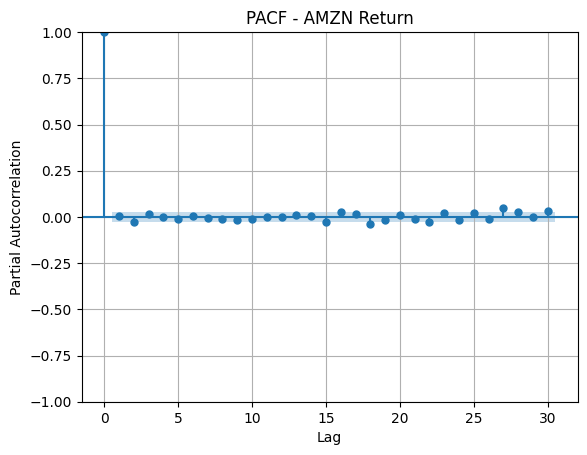

In [41]:
from statsmodels.graphics.tsaplots import plot_pacf
import matplotlib.pyplot as plt

train_return = train['return'].dropna()

plot_pacf(
    train_return,
    lags=30,
    method='ywm'
)

plt.title('PACF - AMZN Return')
plt.xlabel('Lag')
plt.ylabel('Partial Autocorrelation')
plt.grid(True)
plt.show()

In [12]:
from statsmodels.tsa.stattools import pacf

pacf_values, confint = pacf(
    train_return,
    nlags=30,
    alpha=0.05
)

for lag in range(1, 31):
    lower, upper = confint[lag]

    significant = not (lower <= 0 <= upper)

    print(
        f"Lag {lag:2d}: "
        f"PACF={pacf_values[lag]:.4f}, "
        f"CI=[{lower:.4f}, {upper:.4f}], "
        f"Significant={significant}"
    )

Lag  1: PACF=0.0060, CI=[-0.0205, 0.0326], Significant=False
Lag  2: PACF=-0.0282, CI=[-0.0547, -0.0016], Significant=True
Lag  3: PACF=0.0158, CI=[-0.0107, 0.0424], Significant=False
Lag  4: PACF=-0.0027, CI=[-0.0292, 0.0239], Significant=False
Lag  5: PACF=-0.0090, CI=[-0.0356, 0.0175], Significant=False
Lag  6: PACF=0.0074, CI=[-0.0191, 0.0340], Significant=False
Lag  7: PACF=-0.0042, CI=[-0.0307, 0.0224], Significant=False
Lag  8: PACF=-0.0137, CI=[-0.0403, 0.0129], Significant=False
Lag  9: PACF=-0.0140, CI=[-0.0406, 0.0125], Significant=False
Lag 10: PACF=-0.0086, CI=[-0.0352, 0.0179], Significant=False
Lag 11: PACF=-0.0026, CI=[-0.0292, 0.0240], Significant=False
Lag 12: PACF=0.0004, CI=[-0.0262, 0.0269], Significant=False
Lag 13: PACF=0.0100, CI=[-0.0166, 0.0366], Significant=False
Lag 14: PACF=0.0055, CI=[-0.0211, 0.0320], Significant=False
Lag 15: PACF=-0.0286, CI=[-0.0551, -0.0020], Significant=True
Lag 16: PACF=0.0262, CI=[-0.0004, 0.0527], Significant=False
Lag 17: PACF=0.

In [ ]:
import pandas as pd
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

p_candidates = [2, 15, 16, 18, 22, 27, 28, 30]
q_candidates = [2, 15, 16, 18, 22, 27, 28, 30]

results = []

train_return = train['return'].dropna()
val_return = val['return'].dropna()

for p in p_candidates:
    for q in q_candidates:

        try:
            model = ARIMA(
                train_return,
                order=(p, 0, q)
            )

            fitted = model.fit()

            forecast = fitted.forecast(
                steps=len(val_return)
            )

            rmse = np.sqrt(
                mean_squared_error(
                    val_return,
                    forecast
                )
            )

            mae = mean_absolute_error(
                val_return,
                forecast
            )

            results.append({
                'p': p,
                'd': 0,
                'q': q,
                'RMSE': rmse,
                'MAE': mae,
                'AIC': fitted.aic
            })

            print(
                f"ARIMA({p},0,{q}) "
                f"→ RMSE={rmse:.6f}, "
                f"MAE={mae:.6f}"
            )

        except Exception as e:
            print(
                f"ARIMA({p},0,{q}) → FAILED: {e}"
            )

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    'RMSE'
).reset_index(drop=True)

print("\n=== TOP MODELS ===")
print(results_df.head(10))

Vì chạy kiểm tra với các tổ hợp p q lâu nên thống kê ra được một vài tổ hợp cho kết quả tốt nhất để test

In [13]:
results_df = pd.DataFrame([
    [2, 0, 2, 0.019292, 0.013489],
    [2, 0, 15, 0.019302, 0.013498],
    [2, 0, 16, 0.019307, 0.013503],
    [2, 0, 18, 0.019317, 0.013515],
    [2, 0, 22, 0.019326, 0.013519],
    [2, 0, 27, 0.019331, 0.013511],
    [2, 0, 28, 0.019329, 0.013512],
    [2, 0, 30, 0.019332, 0.013517],

    [15, 0, 2, 0.019304, 0.013500],
    [15, 0, 15, 0.019305, 0.013503],
    [15, 0, 16, 0.019303, 0.013498],
    [15, 0, 18, 0.019342, 0.013534],
    [15, 0, 22, 0.019300, 0.013489],
    [15, 0, 27, 0.019348, 0.013521],
    [15, 0, 28, 0.019348, 0.013519],
    [15, 0, 30, 0.019355, 0.013533],

    [16, 0, 2, 0.019304, 0.013499],
    [16, 0, 15, 0.019296, 0.013491],
    [16, 0, 16, 0.019308, 0.013503],
    [16, 0, 18, 0.019331, 0.013525],
    [16, 0, 22, 0.019300, 0.013492],
    [16, 0, 27, 0.019356, 0.013528],
    [16, 0, 28, 0.019357, 0.013527],
    [16, 0, 30, 0.019370, 0.013546],

    [18, 0, 2, 0.019313, 0.013509],
], columns=['p', 'd', 'q', 'RMSE', 'MAE'])

results_df = results_df.sort_values('RMSE').reset_index(drop=True)

results_df

,p,d,q,RMSE,MAE
0,2,0,2,0.019292,0.013489
1,16,0,15,0.019296,0.013491
2,16,0,22,0.019300,0.013492
3,15,0,22,0.019300,0.013489
4,2,0,15,0.019302,0.013498
5,15,0,16,0.019303,0.013498
6,15,0,2,0.019304,0.013500
7,16,0,2,0.019304,0.013499
8,15,0,15,0.019305,0.013503
9,2,0,16,0.019307,0.013503


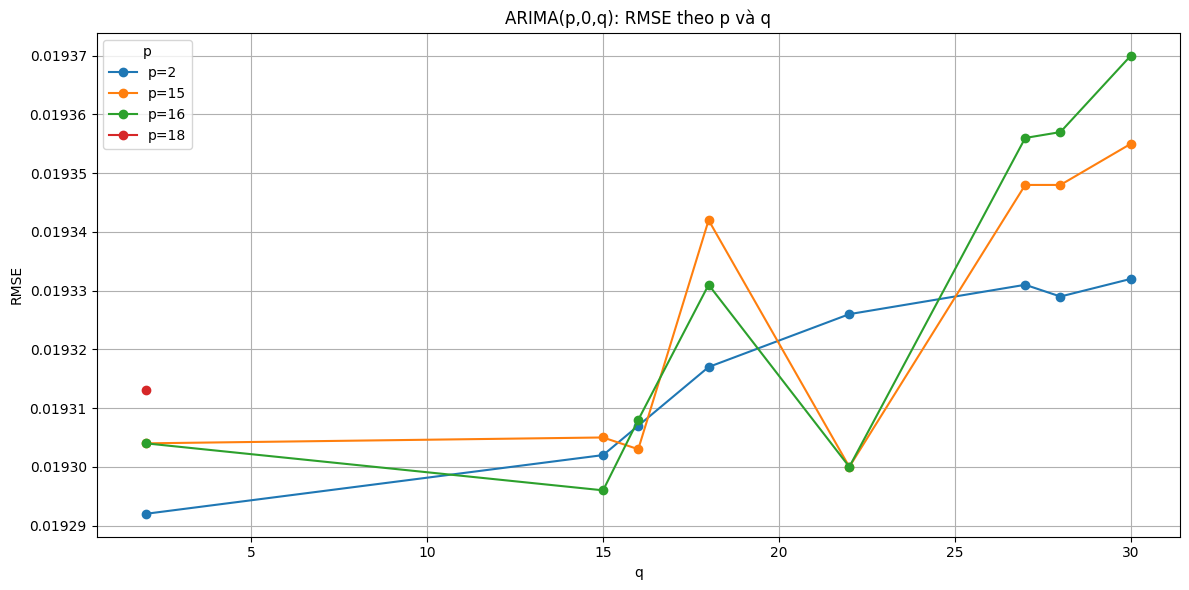

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

for p in sorted(results_df['p'].unique()):
    data = results_df[results_df['p'] == p].sort_values('q')
    
    plt.plot(
        data['q'],
        data['RMSE'],
        marker='o',
        label=f'p={p}'
    )

plt.xlabel('q')
plt.ylabel('RMSE')
plt.title('ARIMA(p,0,q): RMSE theo p và q')
plt.legend(title='p')
plt.grid(True)

plt.tight_layout()
plt.show()

Train cuối


In [15]:
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error, mean_absolute_error

# =========================
# 1. Train + Validation
# =========================

train_val_return = pd.concat([
    train['return'],
    val['return']
]).dropna().reset_index(drop=True)

# =========================
# 2. Test
# =========================

test_return = (
    test['return']
    .dropna()
    .reset_index(drop=True)
)

# =========================
# 3. Fit ARIMA
# =========================

model = ARIMA(
    train_val_return,
    order=(2, 0, 2)
).fit()

# =========================
# 4. Forecast
# =========================

forecast_test = model.forecast(
    steps=len(test_return)
)

# =========================
# 5. Evaluation
# =========================

test_rmse = np.sqrt(
    mean_squared_error(test_return, forecast_test)
)

test_mae = mean_absolute_error(
    test_return,
    forecast_test
)

print("Test RMSE:", test_rmse)
print("Test MAE:", test_mae)

print("\nForecast NaN:", forecast_test.isna().sum())
print("Forecast length:", len(forecast_test))
print("Actual length:", len(test_return))

Test RMSE: 0.019292347630222355
Test MAE: 0.01348930010481068

Forecast NaN: 0
Forecast length: 309
Actual length: 309


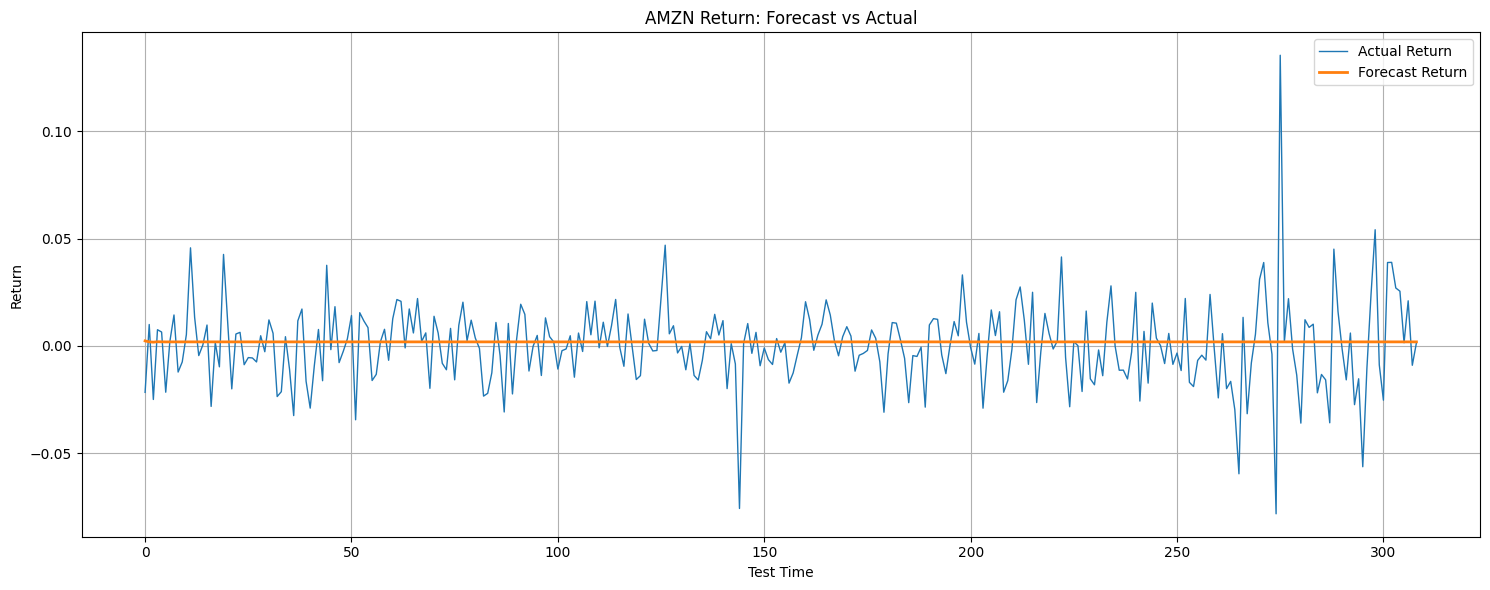

In [16]:
plt.figure(figsize=(15, 6))

plt.plot(
    test_return.values,
    label='Actual Return',
    linewidth=1
)

plt.plot(
    forecast_test.values,
    label='Forecast Return',
    linewidth=2
)

plt.title('AMZN Return: Forecast vs Actual')
plt.xlabel('Test Time')
plt.ylabel('Return')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

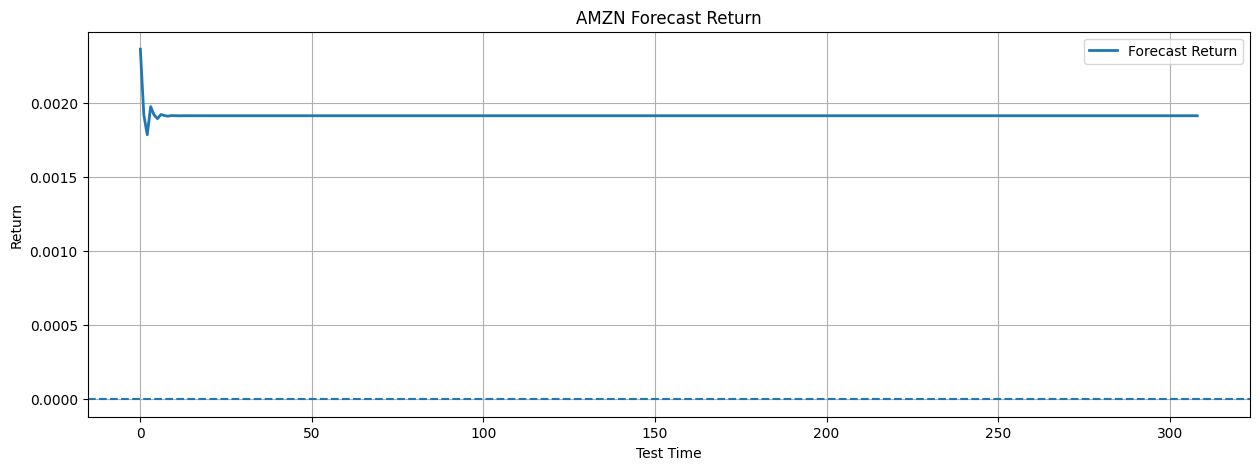

In [17]:
plt.figure(figsize=(15, 5))

plt.plot(
    forecast_test.values,
    linewidth=2,
    label='Forecast Return'
)

plt.axhline(
    y=0,
    linestyle='--'
)

plt.title('AMZN Forecast Return')
plt.xlabel('Test Time')
plt.ylabel('Return')
plt.legend()
plt.grid(True)

plt.show()

Đánh giá dựa trên từng step (kết quả của step này làm input cho step sau ...) thay vì dự đoán trên step của tập test (toàn bộ test ~ 300 bước) do có sai số ở mỗi step làm cộng dồn vào step sau.

In [18]:
import numpy as np
import pandas as pd
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error, mean_absolute_error

# =========================
# 1. Train + Validation
# =========================

train_val_return = pd.concat([
    train['return'],
    val['return']
]).dropna().reset_index(drop=True)

test_return = (
    test['return']
    .dropna()
    .reset_index(drop=True)
)

# =========================
# 2. One-step-ahead forecast
# =========================

history = train_val_return.tolist()
predictions = []

for actual in test_return:

    # Fit model với dữ liệu hiện tại
    model = ARIMA(
        history,
        order=(2, 0, 2)
    ).fit()

    # Chỉ forecast 1 bước
    forecast = model.forecast(steps=1)

    predicted = forecast[0]

    predictions.append(predicted)

    # Sau khi dự báo xong mới thêm actual
    history.append(actual)

# Convert thành Series
forecast_return = pd.Series(predictions)

# =========================
# 3. Evaluation
# =========================

rmse = np.sqrt(
    mean_squared_error(
        test_return,
        forecast_return
    )
)

mae = mean_absolute_error(
    test_return,
    forecast_return
)

print("One-step-ahead RMSE:", rmse)
print("One-step-ahead MAE:", mae)

/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood op

One-step-ahead RMSE: 0.01930721191808777
One-step-ahead MAE: 0.013475523537282012


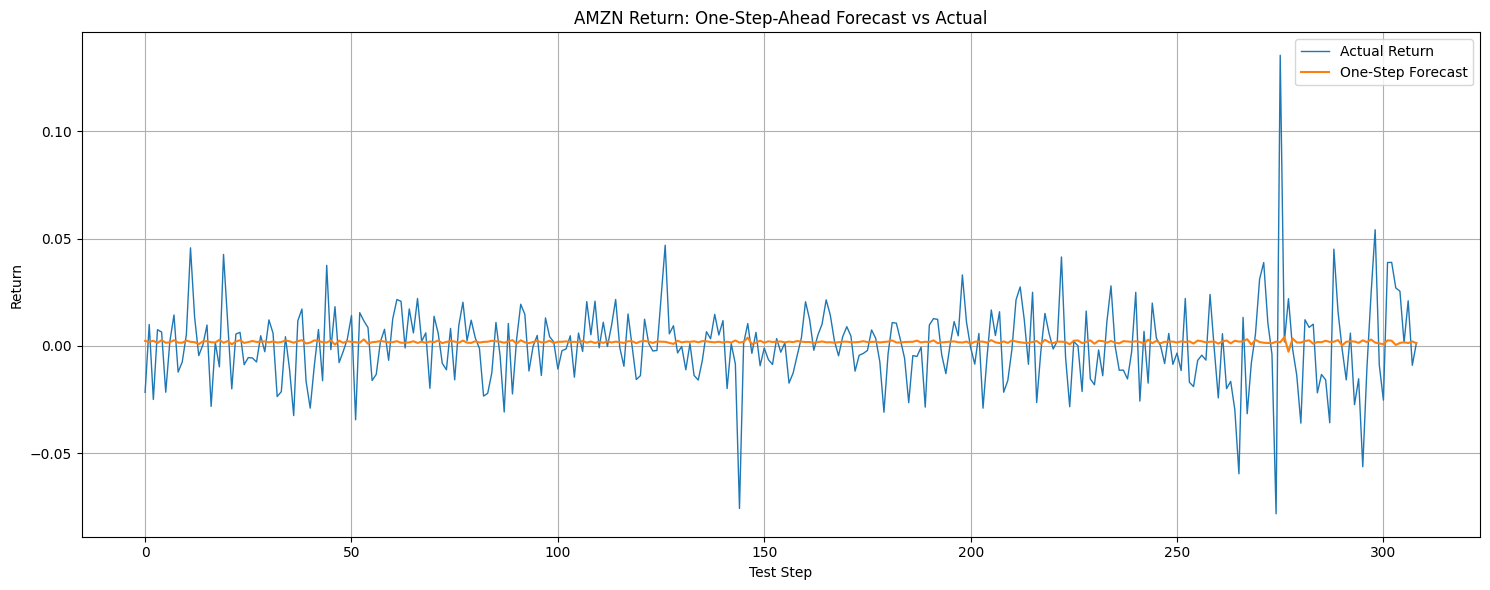

In [82]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

plt.plot(
    test_return.values,
    label='Actual Return',
    linewidth=1
)

plt.plot(
    forecast_return.values,
    label='One-Step Forecast',
    linewidth=1.5
)

plt.title('AMZN Return: One-Step-Ahead Forecast vs Actual')
plt.xlabel('Test Step')
plt.ylabel('Return')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

Đổi ra giá dựa trên return, 

ví dụ:

giá ngày 0 (dữ liệu ban đầu) + return ngày 1 (dự đoán) -> giá của ngày 1

giá của ngày 1 + return ngày 2 -> giá ngày 2

giá ngày 2 + return ngày 3 -> ....

In [88]:
# =========================
# Recursive Return -> Price
# =========================

# Giá cuối cùng của Train + Validation
last_price = pd.concat([
    train['Adj Close'],
    val['Adj Close']
]).dropna().iloc[-1]

forecast_price = []

previous_price = last_price

for predicted_return in forecast_return:

    # P_hat(t) = P_hat(t-1) * (1 + r_hat(t))
    predicted_price = previous_price * (1 + predicted_return)

    forecast_price.append(predicted_price)

    # Quan trọng:
    # bước tiếp theo dùng GIÁ DỰ BÁO
    previous_price = predicted_price

forecast_price = pd.Series(forecast_price)

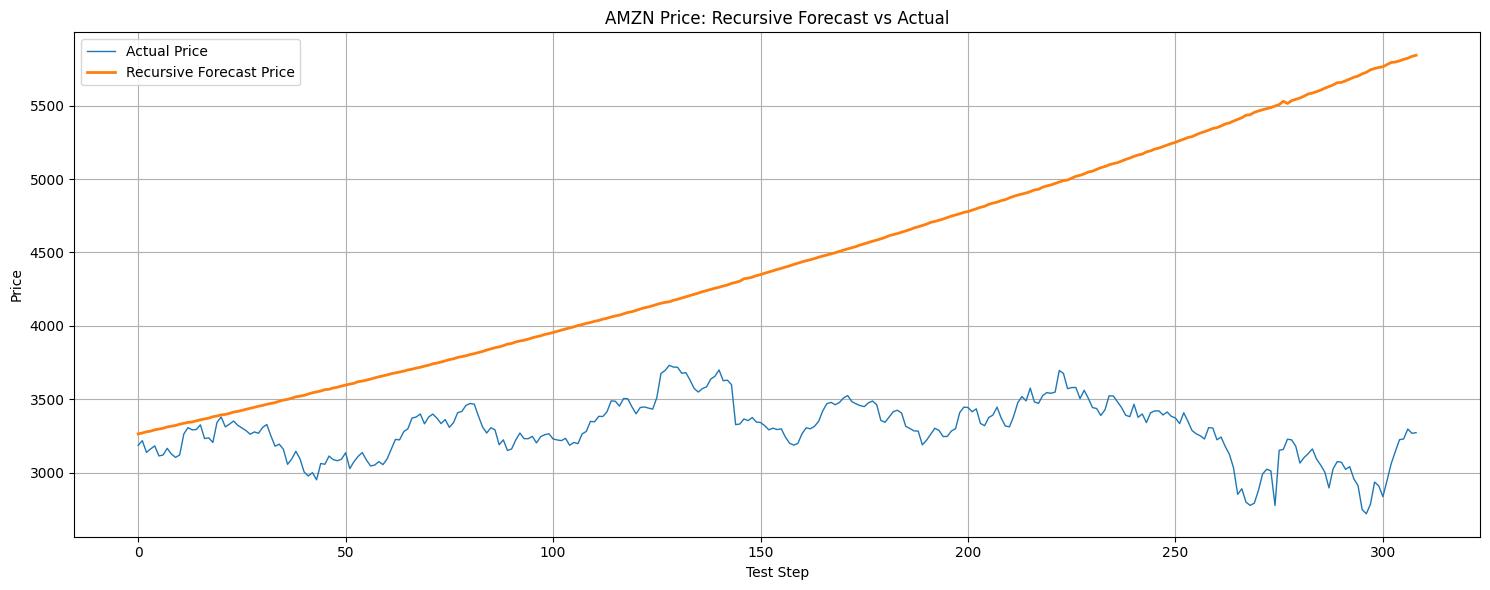

In [90]:
import matplotlib.pyplot as plt

test_price = (
    test['Adj Close']
    .dropna()
    .reset_index(drop=True)
)

plt.figure(figsize=(15, 6))

plt.plot(
    test_price.values,
    label='Actual Price',
    linewidth=1
)

plt.plot(
    forecast_price.values,
    label='Recursive Forecast Price',
    linewidth=2
)

plt.title('AMZN Price: Recursive Forecast vs Actual')
plt.xlabel('Test Step')
plt.ylabel('Price')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()